# Can Quantum Kernels Improve EEG-Based Mental Workload Classification?

## Introduction

The **STEW (Simultaneous Task EEG Workload) dataset** contains electroencephalography (EEG) recordings from 48 participants under resting and multitasking conditions. The signals were recorded using a 14-channel EEG headset at a sampling rate of 128 Hz, with the aim of studying mental workload.

The objective of this project is to compare different machine learning approaches for classifying mental workload (high or low) using the STEW dataset. In particular, we investigate the impact of two dimensionality reduction and feature selection techniques, **Principal Component Analysis (PCA)** and **ANOVA-based feature selection**, combined with different classification models studied in our course. By evaluating their performance using appropriate classification metrics, we aim to identify which combinations achieve the best results.

Article presenting the dataset, with the acquisition methods and a data analysis: [Lim et al, 2018](https://pubmed.ncbi.nlm.nih.gov/30281467/)

Original Dataset (in EDF format) from: [STEW: Simultaneous Tast EEG Dataset](https://ieee-dataport.org/open-access/stew-simultaneous-task-eeg-workload-dataset)

## Project Workflow

The first stage of this project consists of data preprocessing and feature extraction. Each EEG sample contains recordings from 14 channels over 2 seconds, sampled at 128 Hz, resulting in 256 data points per channel and a total of 3,584 raw features per sample ($14 \times 2 \times 128$).

To reduce the dimensionality of the data while preserving relevant information, we extract 15 features from each EEG channel, resulting in a total of 210 features per sample ($14 \times 15$). These features describe the signals in both the time and frequency domains. They include statistical measures such as the mean, standard deviation, variance, root mean square (RMS), skewness, and kurtosis, as well as frequency-band power, relative power in the delta, theta, alpha, beta, and gamma bands, and spectral entropy.

This feature extraction step transforms the raw EEG signals into a more compact and informative representation, which will then be used to compare PCA and ANOVA-based feature selection in combination with different machine learning classifiers.

The second stage focuses on building machine learning pipelines for the different combinations of feature selection or dimensionality reduction techniques and classification models. For each model, we define a set of hyperparameters to explore in order to identify the most effective configurations.

We then split the dataset into training and testing sets, using a StratifiedGroupKFold strategy to preserve class proportions while accounting for participant groups. This helps prevent data leakage between training and validation folds. Next, we perform GridSearchCV to systematically evaluate the different hyperparameter combinations through cross-validation and select the best-performing configuration for each pipeline.

Once the grid search is complete, we present the results in a table summarizing the main performance metrics for each model and configuration. We also generate visualizations, including model performance comparisons, standard deviation plots to assess the variability of cross-validation scores, and confusion matrices to examine classification errors in greater detail.

Finally, we conduct an in-depth analysis of the results to compare the different approaches, assess the impact of PCA and ANOVA-based feature selection on classification performance, and identify which combinations of techniques and models provide the most reliable results.

# Project

In [1]:
import os

from huggingface_hub import hf_hub_download

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.stats import skew, kurtosis

from sklearn.base import clone

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.decomposition import PCA

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, f1_score, confusion_matrix

/home/maxence/Desktop/university/fourth-year/hoai/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Preprocessing
### Data Loading

Preprocessed dataset from: [monster-monash/STEW](https://huggingface.co/datasets/monster-monash/STEW)

In [2]:
REPO_ID = "monster-monash/STEW"

def download_file(filename):
    return hf_hub_download(repo_id=REPO_ID,filename=filename,repo_type="dataset")

X_path = download_file("STEW_X.npy")

Y_path = download_file("STEW_y.csv")

SUBJECT_ID_path = download_file("STEW_subject_id.csv")

X = np.load(X_path)
Y = pd.read_csv(Y_path, header= None).squeeze().to_numpy()
SUBJECT_ID = pd.read_csv(SUBJECT_ID_path, header=None).squeeze().to_numpy()

### Data Exploration

In [3]:
# We verify the shapes of the three arrays

assert(X.ndim == 3)
assert(X.shape == (28512,14,256)) # Expected shape from the tabular dataset description
assert(len(X)==len(Y)==len(SUBJECT_ID))

We make plots to get a better sense of how the data is structured

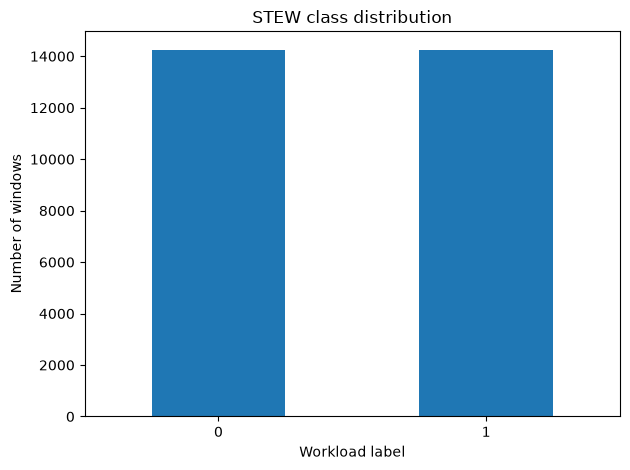

In [4]:
label_counts = pd.Series(Y).value_counts().sort_index()

label_counts.plot(kind="bar")
plt.xlabel("Workload label")
plt.ylabel("Number of windows")
plt.title("STEW class distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

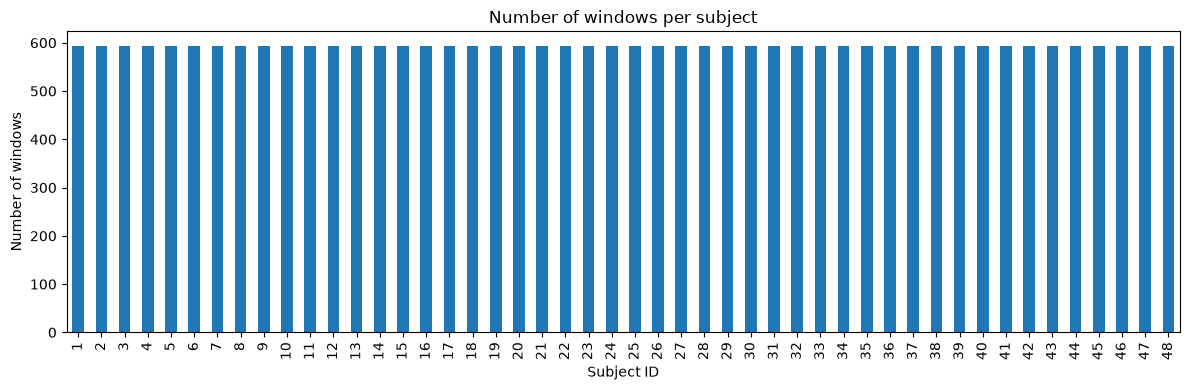

In [5]:
subject_counts = pd.Series(SUBJECT_ID).value_counts().sort_index()

subject_counts.plot(kind="bar", figsize=(12, 4))
plt.xlabel("Subject ID")
plt.ylabel("Number of windows")
plt.title("Number of windows per subject")
plt.tight_layout()
plt.show()

In [6]:
EEG_CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
SAMPLING_FREQUENCY = 128

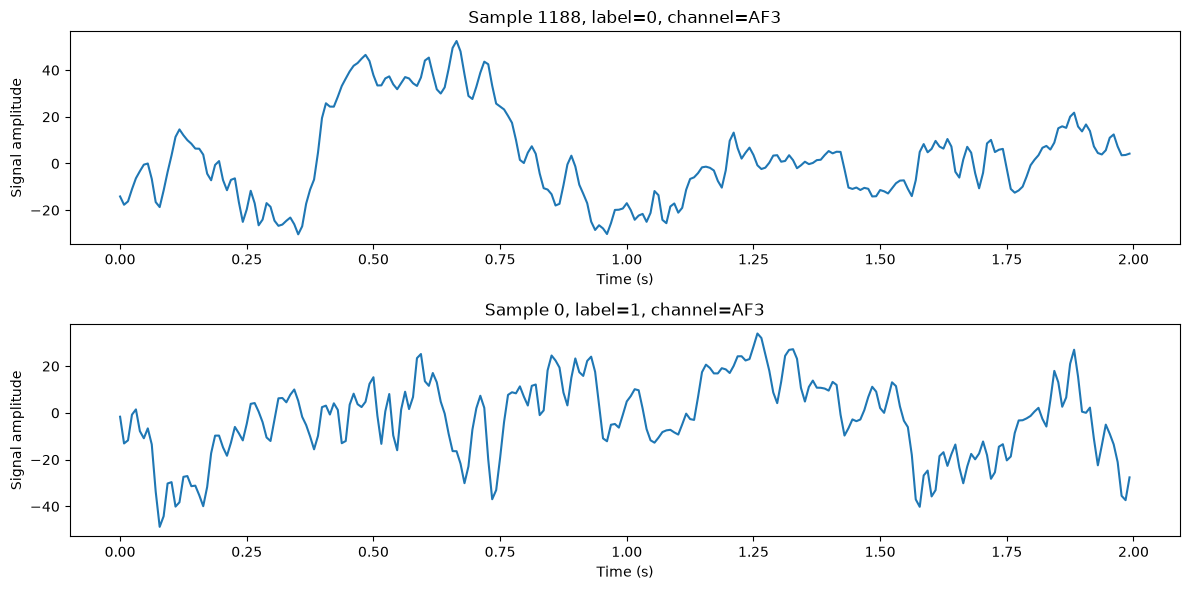

In [7]:
# Find one example for each label
sample_indices = [
    np.flatnonzero(Y == label)[0]
    for label in np.unique(Y)
]

time = np.arange(X.shape[2]) / SAMPLING_FREQUENCY

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

for ax, idx in zip(axes, sample_indices):
    ax.plot(time, X[idx, 0, :])
    ax.set_title(f"Sample {idx}, label={Y[idx]}, channel={EEG_CHANNELS[0]}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Signal amplitude")

plt.tight_layout()
plt.show()

We can see that the data is equally divided by workload classes and that the same amount of samples exists for each subject.

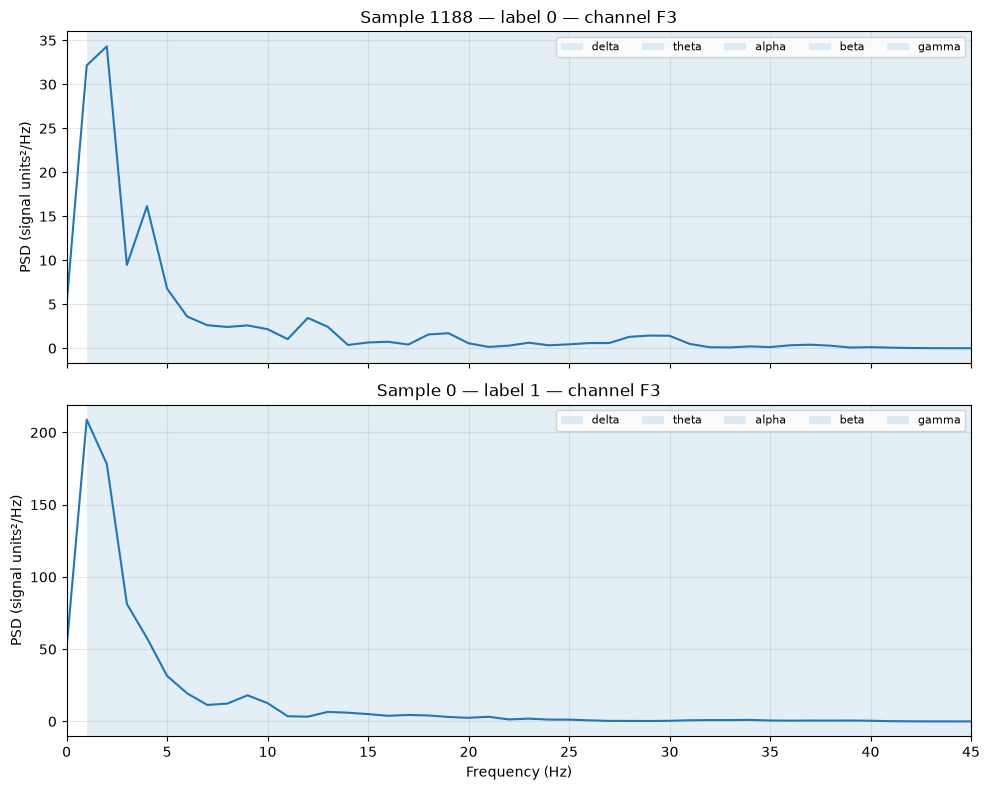

In [8]:
FREQUENCY_BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "beta": (12, 30),
    "gamma": (30, 50),
}

# Find one example window for each class
labels = np.unique(Y)
sample_indices = [
    np.flatnonzero(Y == label)[0]
    for label in labels
]

# Plot channel F3 for each example
channel_idx = EEG_CHANNELS.index("F4")

fig, axes = plt.subplots(
    len(sample_indices), 1,
    figsize=(10, 4 * len(sample_indices)),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, idx in zip(axes, sample_indices):
    signal = np.asarray(X[idx, channel_idx, :], dtype=float)

    # Welch PSD estimate
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=128,
        noverlap=64
    )

    ax.plot(freqs, psd)
    ax.set_xlim(0, 45)
    ax.set_ylabel("PSD (signal units²/Hz)")
    ax.set_title(f"Sample {idx} — label {Y[idx]} — channel F3")
    ax.grid(True, alpha=0.3)

    # Shade the conventional frequency bands
    for band_name, (low, high) in FREQUENCY_BANDS.items():
        ax.axvspan(low, high, alpha=0.12, label=band_name)

    # Avoid duplicate legend entries
    handles, legend_labels = ax.get_legend_handles_labels()
    unique = dict(zip(legend_labels, handles))
    ax.legend(unique.values(), unique.keys(), ncol=5, fontsize=8)

axes[-1].set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

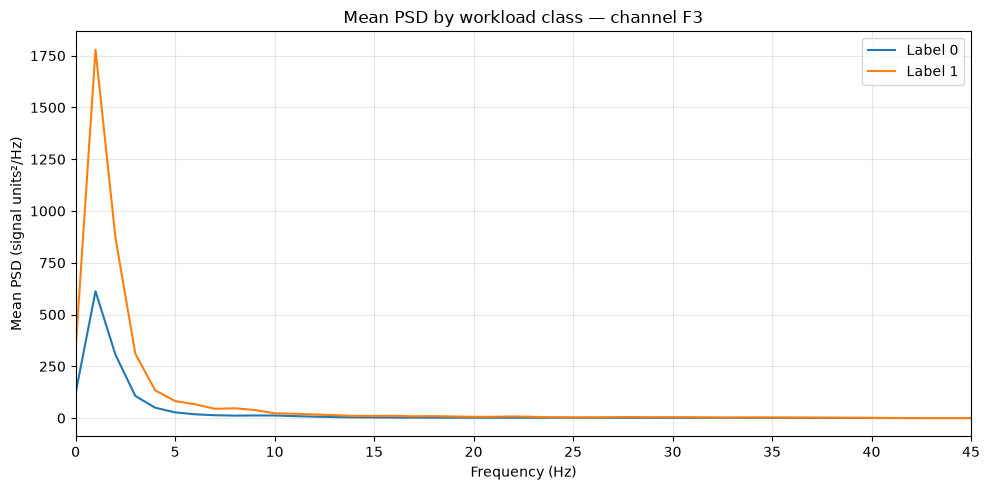

In [9]:
plt.figure(figsize=(10, 5))

channel_idx = EEG_CHANNELS.index("AF4")

for label in np.unique(Y):
    indices = np.flatnonzero(Y == label)

    # Average PSD across windows in this class
    psd_list = []

    for idx in indices:
        signal = np.asarray(X[idx, channel_idx, :], dtype=float)

        freqs, psd = welch(
            signal,
            fs=SAMPLING_FREQUENCY,
            nperseg=128,
            noverlap=64
        )

        psd_list.append(psd)

    mean_psd = np.mean(psd_list, axis=0)

    plt.plot(freqs, mean_psd, label=f"Label {label}")

plt.xlim(0, 45)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Mean PSD (signal units²/Hz)")
plt.title("Mean PSD by workload class — channel F3")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Data Cleaning

We remove all the data from subjects 5, 24, 42, as the dataset presentation article (Lim et al, 2018) states that ratings were not obtained for this subjects.

In [10]:
SUBJECTS_TO_REMOVE=[5,24,42]

mask=np.logical_not(np.isin(SUBJECT_ID,SUBJECTS_TO_REMOVE))
X=X[mask]
Y=Y[mask]
SUBJECT_ID=SUBJECT_ID[mask]

In [11]:
#We test that the removal was successful
for subject in SUBJECTS_TO_REMOVE:
    assert(X[SUBJECT_ID==subject].size==0)
    assert(Y[SUBJECT_ID==subject].size==0)
    assert(SUBJECT_ID[SUBJECT_ID==subject].size==0)

    assert(X[SUBJECT_ID==(subject-1)].size!=0)
    assert(Y[SUBJECT_ID==(subject-1)].size!=0)
    assert(SUBJECT_ID[SUBJECT_ID==(subject-1)].size!=0)


assert(X.shape == (28512-28512*3/48,14,256)) # Expected new shape, given that we removed 3/48th of the data
assert(len(X)==len(Y)==len(SUBJECT_ID))

## Feature engineering

We crete a .csv table with the chosen features:

In [12]:
def extract_features(signal):

    # Time-domain features
    new_features = {
        "mean": np.mean(signal),
        "std" : np.std(signal),
        "var" : np.var(signal),
        "rms" : np.sqrt(np.mean(signal**2)),
        "skewness": skew(signal, bias=True),
        "kurtosis": kurtosis(signal, fisher=True, bias=True),
    }
    # Frequency-domain features
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=len(signal)
    )

    frequency_resolution = freqs[1] - freqs[0] 

    total_mask = (freqs >= 1) & (freqs < 45)
    total_power = np.sum(psd[total_mask]) * frequency_resolution

    for band, (low, high) in FREQUENCY_BANDS.items():

        mask = (freqs >= low) & (freqs < high)

        power = (
            np.sum(psd[mask]) * frequency_resolution
            if np.any(mask) else 0.0
        )

        new_features[f"{band}_power"] = power

        new_features[f"{band}_relative_power"] = (
            power / total_power
            if total_power > 1e-12 else 0.0
        )

    # Spectral entropy over the 1–45 Hz range
    psd_band = psd[total_mask]
    power_sum = psd_band.sum()

    if power_sum > 1e-12:
        probabilities = psd_band / power_sum
        probabilities = probabilities[probabilities > 0]

        new_features["spectral_entropy"] = -np.sum(
            probabilities * np.log2(probabilities)
        )
    else:
        new_features["spectral_entropy"] = 0.0

    return new_features

In [13]:
def create_dataset():
    records = []

    for sample_idx in range(len(X)):

        eeg_sample = X[sample_idx]

        record = {
            "sample_id": sample_idx,
            "subject_id": SUBJECT_ID[sample_idx],
        }

        for channel_idx, channel_name in enumerate(EEG_CHANNELS):

            signal = eeg_sample[channel_idx, :]

            channel_features = extract_features(signal)

            for feature_name, value in channel_features.items():
                column_name = f"{channel_name}_{feature_name}"
                record[column_name] = value

        record["label"] = Y[sample_idx]
        records.append(record)

        if (sample_idx + 1) % 1000 == 0:
            print(f"Processed {sample_idx + 1}/{len(X)} examples")

    print(f"Processed {sample_idx + 1}/{len(X)} examples")
    return records

We create a dataframe with the extracted outputs and write it to a .csv file.

In [14]:
DATASET_PATH = "STEW_features.csv"

if(os.path.isfile(DATASET_PATH)):
    DATASET_EXT=pd.read_csv(DATASET_PATH)
else:
    new_dataset=create_dataset()
    DATASET_EXT = pd.DataFrame(new_dataset)
    
    #Automatically overwrites a file of the same name in this directory.
    DATASET_EXT.to_csv(DATASET_PATH, index=False)
    
print(DATASET_EXT.shape)

(28512, 241)


In [15]:
print(DATASET_EXT.head())
print(DATASET_EXT.shape)

   sample_id  subject_id  AF3_mean    AF3_std    AF3_var    AF3_rms  \
0          0          12 -2.364527  16.718996  279.52484  16.885374   
1          1          12  1.513650  15.534682  241.32635  15.608251   
2          2          12  0.492984  14.909048  222.27971  14.917197   
3          3          12 -2.007783  14.349675  205.91318  14.489458   
4          4          12  1.876135  13.039218  170.02121  13.173500   

   AF3_skewness  AF3_kurtosis  AF3_delta_power  AF3_delta_relative_power  ...  \
0     -0.339354     -0.337851       114.806351                  0.573799  ...   
1     -0.468445     -0.308483       185.131073                  0.716253  ...   
2     -0.283593     -0.254668       141.955475                  0.627093  ...   
3     -0.157667     -0.236524        81.054817                  0.508537  ...   
4     -0.063752     -0.338315        59.304790                  0.397247  ...   

   AF4_theta_power  AF4_theta_relative_power  AF4_alpha_power  \
0       323.099518   

## Classical Models

### Pipelines: Features reduction and Model training

We want to analyze the impact of PCA and ANOVA on different SVM models like RBF and Logistic Regression as a guideline.

#### Hyperparameters

In [16]:
# Fixed seed so that all results are reproducible
RANDOM_STATE = 42

# Feature subset sizes to compare (the smallest ones go to the quantum SVM)
CANDIDATE_KS = [5, 10, 20, 50, 100]

# Main metric used to compare the methods
SCORING = 'f1_weighted'

#### Train Test Split

In [17]:
# Separate features, target and subject ids.
# subject_id is NOT a feature, but we keep it as `groups` so that the
# cross-validation never puts the same person in both train and test.
X_ = DATASET_EXT.drop(columns=['sample_id', 'subject_id', 'label'])
y_ = DATASET_EXT['label']
subjects = DATASET_EXT['subject_id']

UNIQUE_SUBJECTS = np.unique(subjects)

SUB_train, SUB_test = train_test_split(
    UNIQUE_SUBJECTS,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print(SUB_train.shape)
print(SUB_test.shape)

# Train matrix
train=np.isin(subjects, SUB_train)
X_train=X_[train]
y_train=y_[train]
subjects_train = subjects[train]

print(X_train.shape)
print(y_train.shape)

# Test matrix
test=np.isin(subjects, SUB_test)
X_test=X_[test]
y_test=y_[test]
subjects_test = subjects[test]

print(X_test.shape)
print(y_test.shape)

# Make sure the data is clean before any modelling
assert X_.isna().sum().sum() == 0, "NaN values found in features"
assert all(np.issubdtype(t, np.number) for t in X_.dtypes), "Non-numeric columns found"

# Grouped, stratified CV: no subject appears in both train and validation folds.
# The same object is used for both methods, so they see identical splits.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(36,)
(12,)
(21384, 238)
(21384,)
(7128, 238)
(7128,)


#### Pipelines

In [33]:
# All reducers
reducers = {
    "ANOVA": (
        SelectKBest(score_func=f_classif),
        {"reducer__k": CANDIDATE_KS},
    ),
    "PCA": (
        PCA(),
        {"reducer__n_components": CANDIDATE_KS},
    ),
    "None": (
        "passthrough",
        {},
    ),
}

In [34]:
# All classifiers
classifiers = {
    "SVC": (
        SVC(),
        {
            "classifier__kernel": ["rbf"],
            "classifier__C": [0.1, 1, 10, 100],
            #"classifier__gamma": ["scale", 0.01, 0.1, 1],
        },
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {
            "classifier__C": [0.1, 1, 10, 100],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=1),
        {
            "classifier__n_estimators": [100, 300],
            "classifier__max_depth": [None, 20],
        },
    ),    
}

In [20]:
searches = {}
results = []

for reducer_name, (reducer, reducer_grid) in reducers.items():
    for classifier_name, (classifier, classifier_grid) in classifiers.items():
        name = f"{reducer_name} + {classifier_name}"

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("reducer", reducer),
            ("classifier", classifier),
        ])

        param_grid = {
            **reducer_grid,
            **classifier_grid,
        }

        print(f"\nExecuting GridSearchCV: {name}")

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            cv=cv,
            scoring=SCORING,
            n_jobs=-1,
            verbose=1,
        )

        search.fit(X_train, y_train, groups=subjects_train)

        searches[name] = search

        results.append({
            "Model": name,
            "Best CV F1-weighted": search.best_score_,
            "Best parameters": search.best_params_,
        })

        print(f"- Best score: {search.best_score_:.4f}")
        print(f"- Best parameters: {search.best_params_}")


Executing GridSearchCV: None + Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
- Best score: 0.7187
- Best parameters: {'classifier__C': 100}


### Results

#### Scores table

In [21]:
comparison_results = []

for name, search in searches.items():
    print(name)
    cv_results = pd.DataFrame(search.cv_results_)

    # Identify the dimensionality parameter, if available
    if (
        "param_reducer__k" in cv_results.columns
        and cv_results["param_reducer__k"].notna().any()
    ):
        dim_param = "param_reducer__k"

    elif (
        "param_reducer__n_components" in cv_results.columns
        and cv_results["param_reducer__n_components"].notna().any()
    ):
        dim_param = "param_reducer__n_components"

    else:
        dim_param = None

    # Reducer with a dimensionality parameter (ANOVA / PCA)
    if dim_param is not None:

        best_by_dim = (
            cv_results
            .dropna(subset=[dim_param, "mean_test_score"])
            .loc[
                lambda df: df.groupby(dim_param)["mean_test_score"].idxmax()
            ]
            .sort_values(dim_param)
        )

    # No reducer (None)
    else:
        best_idx = cv_results["mean_test_score"].idxmax()
        best_by_dim = cv_results.loc[[best_idx]]

    # Store the results
    for _, row in best_by_dim.iterrows():
        comparison_results.append({
            "Model": name,
            "k": row[dim_param] if dim_param is not None else X_.shape[1],
            "F1_mean": row["mean_test_score"],
            "F1_std": row["std_test_score"],
            "params": row["params"],
        })


# Build the results DataFrame
results_df = pd.DataFrame(comparison_results)

# Preserve None instead of letting pandas convert it to NaN
results_df["k"] = pd.Series(
    [result["k"] for result in comparison_results],
    dtype=object,
)

results_df = (
    results_df
    .sort_values(["Model", "k"], na_position="first")
    .reset_index(drop=True)
)

results_df.to_csv(
    "all_models_f1_by_dimension.csv",
    index=False,
    na_rep="None",
)

# Keep the best result for each model
if not results_df.empty:
    best_results_df = (
        results_df.loc[
            results_df.groupby("Model")["F1_mean"].idxmax()
        ]
        .sort_values("F1_mean", ascending=False)
        .reset_index(drop=True)
    )

    best_results_df.to_csv(
        "best_results_by_model.csv",
        index=False,
        na_rep="None",
    )

    display(results_df)
    display(best_results_df)

else:
    print("No results available.")

None + Logistic Regression


,Model,k,F1_mean,F1_std,params
0,None + Logistic Regression,238,0.718663,0.065447,{'classifier__C': 100}


,Model,k,F1_mean,F1_std,params
0,None + Logistic Regression,238,0.718663,0.065447,{'classifier__C': 100}


#### Plotting

In [22]:
def reducer_plot(ax):
    for classifier_name in classifier_names:
        model_name = f"{reducer_name} + {classifier_name}"

        model_results = (
            results_df[results_df["Model"] == model_name]
            .sort_values("k")
        )

        if model_results.empty:
            continue

        means = model_results["F1_mean"]
        stds = model_results["F1_std"]

        ax.errorbar(
            model_results["k"],
            means,
            yerr=stds,
            marker="o",
            color=colors[classifier_name],
            linewidth=2,
            capsize=4,
            label=classifier_name,
        )

    ax.legend(title="Classifier")

In [23]:
def no_reducer_plot(ax):
    labels = []
    means = []
    stds = []
    bar_colors = []

    for classifier_name in classifier_names:
        model_name = f"{reducer_name} + {classifier_name}"

        model_results = results_df[
            results_df["Model"] == model_name
        ]

        if model_results.empty:
            continue

        # Keep the best configuration for this classifier
        best_row = model_results.loc[
            model_results["F1_mean"].idxmax()
        ]

        labels.append(classifier_name)
        means.append(best_row["F1_mean"])
        stds.append(best_row["F1_std"])
        bar_colors.append(colors[classifier_name])

    ax.bar(
        labels,
        means,
        yerr=stds,
        color=bar_colors,
        capsize=4,
        alpha=0.85,
    )

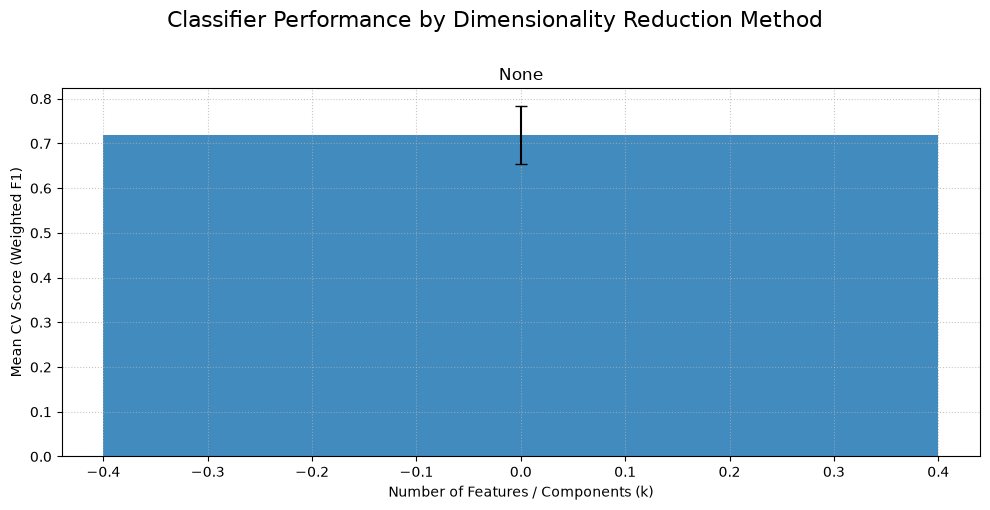

In [24]:
reducer_names = list(reducers.keys())
classifier_names = list(classifiers.keys())

# One color per classifier.
cmap = plt.get_cmap("tab10")
colors = {
    name: cmap(i % cmap.N)
    for i, name in enumerate(classifier_names)
}

fig, axes = plt.subplots(
    nrows=len(reducer_names),
    ncols=1,
    figsize=(10, 5 * len(reducer_names)),
    sharex=False,
    squeeze=False,
)

for row, reducer_name in enumerate(reducer_names):

    ax = axes[row, 0]

    if reducer_name == "None":
        no_reducer_plot(ax) 
    else:
        reducer_plot(ax)

    ax.set_xscale("linear")
    ax.set_title(reducer_name)
    ax.set_xlabel("Number of Features / Components (k)")
    ax.set_ylabel("Mean CV Score (Weighted F1)")
    ax.grid(True, linestyle=":", alpha=0.7)

fig.suptitle(
    "Classifier Performance by Dimensionality Reduction Method",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plt.savefig(
    "classifier_comparison_by_reducer.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

The results show that the **ANOVA + SVM** combination achieves the best performance among the evaluated models. Therefore, we will focus on this combination in greater detail to further investigate its performance and explore potential improvements.

## Best classical Model

In [25]:
# Get the model with the best score
classifiers_score = []
best_score = 0
best_estimator = None

for key, val in searches.items():
    val.best_estimator_.fit(X_train, y_train)
    score = val.best_estimator_.score(X_test, y_test)

    classifiers_score.append((score, val.best_estimator_))

    if best_score < score:
        best_score = score
        best_estimator = val.best_estimator_

In [26]:
for (key, value) in classifiers_score:
    print(key)
    print(value.steps[1][1])
    print(value.get_params().get("reducer__k") or value.get_params().get("reducer__n_components"))
    print()

0.7502805836139169
passthrough
None



## Quantum

In [32]:
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import PegasosQSVC
from sklearn.base import BaseEstimator, ClassifierMixin

# Do not remove, mandantory in order to not have key error later in the fit
X_train=X_train.reset_index(drop=True)
y_train=y_train.reset_index(drop=True)
X_test=X_test.reset_index(drop=True)
y_test=y_test.reset_index(drop=True)

In [28]:
feature_map = zz_feature_map(
    feature_dimension=2,
    reps=2,
    entanglement="linear"
)

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map,
)

pegasos = PegasosQSVC(
    quantum_kernel=quantum_kernel,
    C=1.0,
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("reducer", PCA(n_components=2)),
    ("classifier", pegasos),
])

In [ ]:
pipeline.fit(X_train, y_train)

In [31]:
print("Best parameters:", pipeline)
print("Best F1-weighted:", pipeline)

Best parameters: Pipeline(steps=[('scaler', StandardScaler()), ('reducer', PCA(n_components=2)),
                ('classifier',
                 <qiskit_machine_learning.algorithms.classifiers.pegasos_qsvc.PegasosQSVC object at 0x7f97b6e6d550>)])
Best F1-weighted: Pipeline(steps=[('scaler', StandardScaler()), ('reducer', PCA(n_components=2)),
                ('classifier',
                 <qiskit_machine_learning.algorithms.classifiers.pegasos_qsvc.PegasosQSVC object at 0x7f97b6e6d550>)])
